# 🔍 01 — Data Exploration
### Scouti Kora — AI Football Scouting System
**Goal:** Understand every dataset before building any model.  
**Output:** Clean summary of shape, types, nulls, distributions, and join relationships.

---

## 📦 0 — Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'font.family':      'sans-serif',
    'font.size':        11,
})
COLORS = ['#7F77DD', '#1D9E75', '#D85A30', '#378ADD', '#BA7517', '#D4537E']

# ── Data path ───────────────────────────────────────────
RAW = '../data/raw/'   # adjust if needed

print('✅ Imports ready')
print(f'📁 Looking for data in: {os.path.abspath(RAW)}')

✅ Imports ready
📁 Looking for data in: C:\Users\Yassine\Desktop\scouti_kora\data\raw


## 📂 1 — Load All Datasets

In [2]:
datasets = {
    'players':           'players.csv',
    'player_valuations': 'player_valuations.csv',
    'transfers':         'transfers.csv',
    'appearances':       'appearances.csv',
    'games':             'games.csv',
    'game_events':       'game_events.csv',
    'game_lineups':      'game_lineups.csv',
    'clubs':             'clubs.csv',
    'competitions':      'competitions.csv',
    'club_games':        'club_games.csv',
    'national_teams':    'national_teams.csv',
    'countries':         'countries.csv',
}

dfs = {}
print(f"{'Dataset':<22} {'Rows':>10} {'Cols':>6} {'Size (MB)':>10}")
print('─' * 54)

for name, fname in datasets.items():
    path = RAW + fname
    df   = pd.read_csv(path, low_memory=False)
    dfs[name] = df
    size_mb = os.path.getsize(path) / 1_048_576
    print(f"{name:<22} {len(df):>10,} {len(df.columns):>6}  {size_mb:>8.1f} MB")

total_rows = sum(len(v) for v in dfs.values())
print('─' * 54)
print(f"{'TOTAL':<22} {total_rows:>10,}")

Dataset                      Rows   Cols  Size (MB)
──────────────────────────────────────────────────────
players                    47,702     26      16.0 MB
player_valuations         616,377      6      28.6 MB
transfers                 157,186     10      12.7 MB
appearances             1,862,208     13     139.8 MB
games                      86,983     23      24.5 MB
game_events             1,242,945     11     145.8 MB
game_lineups            3,049,833     10     322.3 MB
clubs                         796     17       0.2 MB
competitions                   67     11       0.0 MB
club_games                173,966     11      10.3 MB
national_teams                118     17       0.0 MB
countries                     118      8       0.0 MB
──────────────────────────────────────────────────────
TOTAL                   7,238,299


## 🧱 2 — Schema Overview (columns per dataset)

In [3]:
for name, df in dfs.items():
    print(f"\n{'═'*60}")
    print(f"  📋 {name.upper()}  ({len(df):,} rows × {len(df.columns)} cols)")
    print(f"{'═'*60}")
    info = pd.DataFrame({
        'column':   df.columns,
        'dtype':    df.dtypes.values,
        'nulls':    df.isnull().sum().values,
        'null_%':   (df.isnull().mean() * 100).round(1).values,
        'unique':   df.nunique().values,
        'sample':   [str(df[c].dropna().iloc[0]) if df[c].notna().any() else 'N/A'
                     for c in df.columns],
    })
    print(info.to_string(index=False))


════════════════════════════════════════════════════════════
  📋 PLAYERS  (47,702 rows × 26 cols)
════════════════════════════════════════════════════════════
                              column   dtype  nulls  null_%  unique                                                                        sample
                           player_id   int64      0    0.00   47702                                                                            10
                          first_name     str   3095    6.50   10300                                                                      Miroslav
                           last_name     str      0    0.00   32482                                                                         Klose
                                name     str      0    0.00   46449                                                                Miroslav Klose
                         last_season   int64      0    0.00      14                                           

## 🚨 3 — Missing Values Heatmap

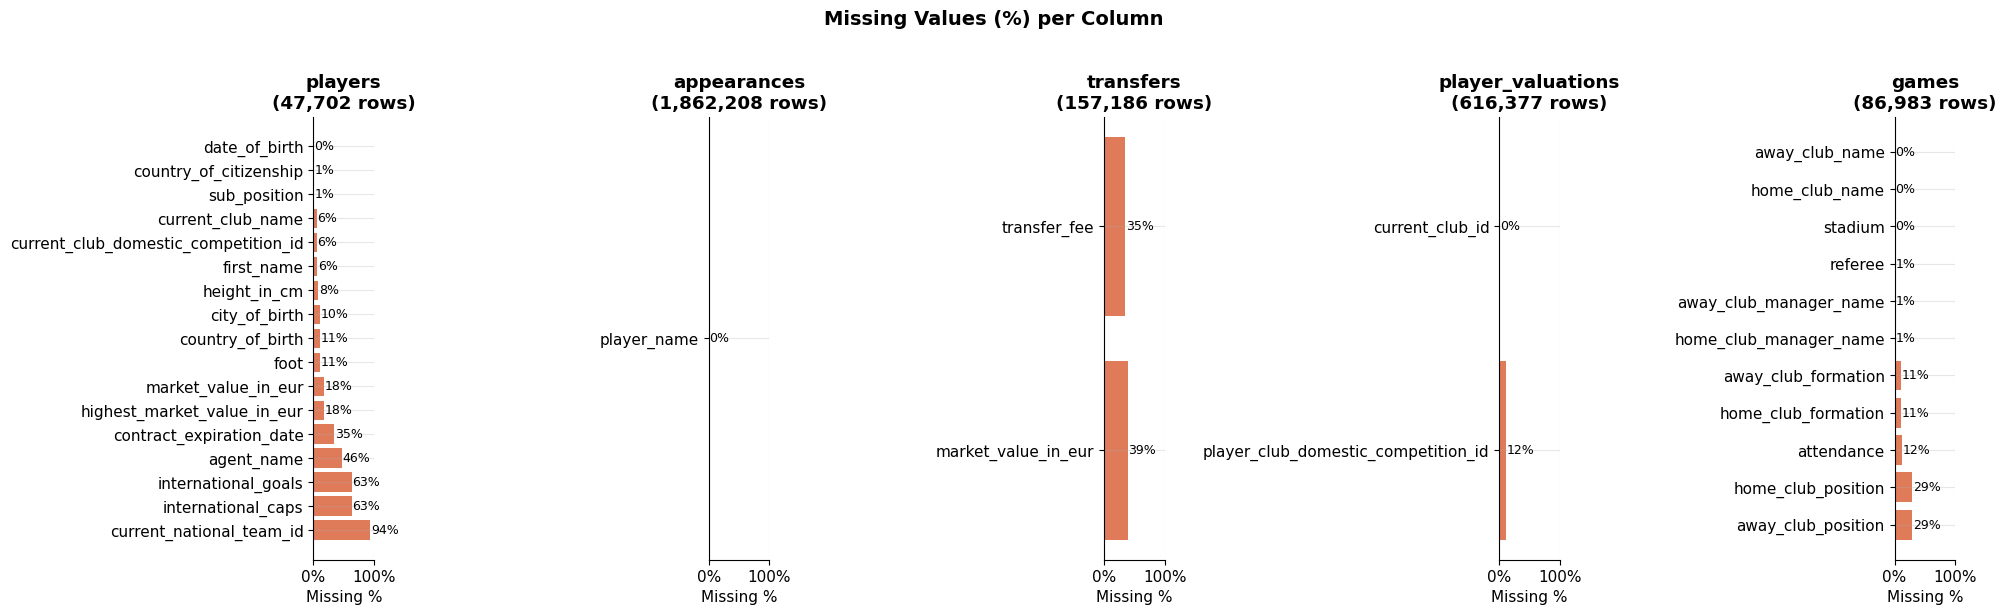

💾 Saved → reports/01_missing_values.png


In [4]:
# Compute null % for key tables
key_tables = ['players', 'appearances', 'transfers', 'player_valuations', 'games']

fig, axes = plt.subplots(1, len(key_tables), figsize=(20, 6))
fig.suptitle('Missing Values (%) per Column', fontsize=14, fontweight='bold', y=1.02)

for ax, name in zip(axes, key_tables):
    df      = dfs[name]
    null_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
    null_pct = null_pct[null_pct > 0]  # only columns with nulls

    if null_pct.empty:
        ax.text(0.5, 0.5, 'No missing\nvalues!',
                ha='center', va='center', transform=ax.transAxes,
                fontsize=12, color='green')
        ax.set_title(name)
        ax.axis('off')
        continue

    bars = ax.barh(null_pct.index, null_pct.values, color='#D85A30', alpha=0.8)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Missing %')
    ax.set_title(f'{name}\n({len(df):,} rows)', fontweight='bold')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())

    for bar, val in zip(bars, null_pct.values):
        ax.text(val + 1, bar.get_y() + bar.get_height()/2,
                f'{val:.0f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/01_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/01_missing_values.png')

## ⚽ 4 — Players Deep Dive

In [5]:
players = dfs['players'].copy()
players['date_of_birth'] = pd.to_datetime(players['date_of_birth'], errors='coerce')
players['age'] = ((pd.Timestamp.now() - players['date_of_birth']).dt.days / 365.25).round(1)

print('── Players overview ──────────────────────────────────')
print(players[['name','age','position','sub_position','foot',
               'height_in_cm','market_value_in_eur',
               'current_club_name']].head(10).to_string(index=False))

── Players overview ──────────────────────────────────
               name   age   position       sub_position  foot  height_in_cm  market_value_in_eur                                       current_club_name
     Miroslav Klose 47.90     Attack     Centre-Forward right        184.00           1000000.00                           Società Sportiva Lazio S.p.A.
 Roman Weidenfeller 45.70 Goalkeeper         Goalkeeper  left        190.00            750000.00                                       Borussia Dortmund
   Dimitar Berbatov 45.20     Attack     Centre-Forward   NaN           NaN           1000000.00 Panthessalonikios Athlitikos Omilos Konstantinoupoliton
              Lúcio 47.90   Defender        Centre-Back   NaN           NaN            200000.00                                  Juventus Football Club
         Tom Starke 45.10 Goalkeeper         Goalkeeper right        194.00            100000.00                                       FC Bayern München
               Dedê 48.00  

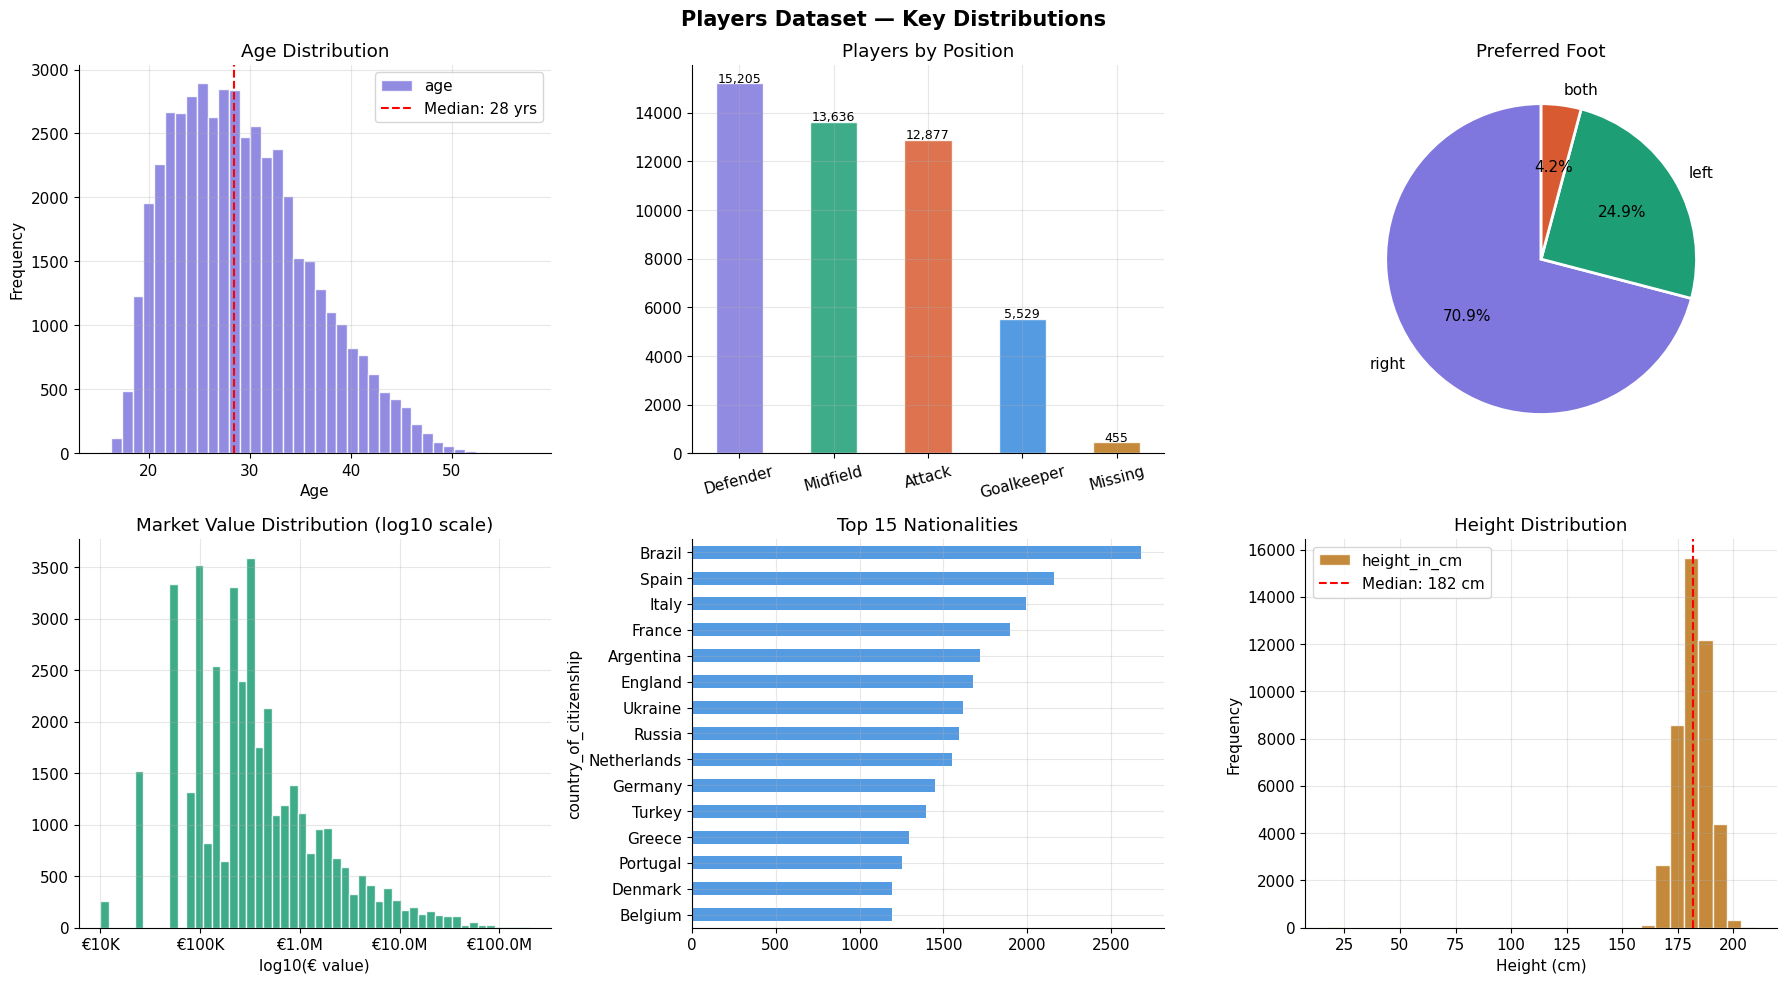

💾 Saved → reports/02_players_distributions.png


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Players Dataset — Key Distributions', fontsize=15, fontweight='bold')

# 4a. Age distribution
ax = axes[0, 0]
players['age'].dropna().plot.hist(bins=40, ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.axvline(players['age'].median(), color='red', linestyle='--', label=f"Median: {players['age'].median():.0f} yrs")
ax.set_title('Age Distribution')
ax.set_xlabel('Age')
ax.legend()

# 4b. Position breakdown
ax = axes[0, 1]
pos_counts = players['position'].value_counts()
pos_counts.plot.bar(ax=ax, color=COLORS[:len(pos_counts)], alpha=0.85, edgecolor='white')
ax.set_title('Players by Position')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{int(bar.get_height()):,}', ha='center', fontsize=9)

# 4c. Preferred foot
ax = axes[0, 2]
foot_counts = players['foot'].value_counts()
ax.pie(foot_counts.values, labels=foot_counts.index, autopct='%1.1f%%',
       colors=COLORS[:len(foot_counts)], startangle=90,
       wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.set_title('Preferred Foot')

# 4d. Market value distribution (log scale)
ax = axes[1, 0]
vals = players['market_value_in_eur'].dropna()
vals = vals[vals > 0]
ax.hist(np.log10(vals), bins=50, color=COLORS[1], alpha=0.85, edgecolor='white')
ax.set_title('Market Value Distribution (log10 scale)')
ax.set_xlabel('log10(€ value)')
ax.set_xticklabels([f'€{10**x/1e6:.1f}M' if x >= 6 else f'€{10**x/1e3:.0f}K'
                    for x in ax.get_xticks()])

# 4e. Top 15 nationalities
ax = axes[1, 1]
top_nations = players['country_of_citizenship'].value_counts().head(15)
top_nations.plot.barh(ax=ax, color=COLORS[3], alpha=0.85)
ax.set_title('Top 15 Nationalities')
ax.invert_yaxis()

# 4f. Height distribution
ax = axes[1, 2]
players['height_in_cm'].dropna().plot.hist(
    bins=30, ax=ax, color=COLORS[4], alpha=0.85, edgecolor='white')
ax.axvline(players['height_in_cm'].median(), color='red', linestyle='--',
           label=f"Median: {players['height_in_cm'].median():.0f} cm")
ax.set_title('Height Distribution')
ax.set_xlabel('Height (cm)')
ax.legend()

plt.tight_layout()
plt.savefig('../reports/02_players_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/02_players_distributions.png')

## 💶 5 — Market Value Analysis

In [7]:
vals = dfs['player_valuations'].copy()
vals['date'] = pd.to_datetime(vals['date'], errors='coerce')
vals['year'] = vals['date'].dt.year

# Top 10 most valued players right now
top_valued = (
    players.nlargest(10, 'market_value_in_eur')
    [['name','position','current_club_name',
      'country_of_citizenship','market_value_in_eur','age']]
    .assign(market_value_in_eur=lambda x: x['market_value_in_eur'] / 1e6)
    .rename(columns={'market_value_in_eur': 'value_M_eur'})
)
print('💎 Top 10 Most Valued Players:')
print(top_valued.to_string(index=False))

💎 Top 10 Most Valued Players:
             name position             current_club_name country_of_citizenship  value_M_eur   age
    Kylian Mbappé   Attack    Real Madrid Club de Fútbol                 France       200.00 27.30
   Erling Haaland   Attack Manchester City Football Club                 Norway       200.00 25.70
     Lamine Yamal   Attack         Futbol Club Barcelona                  Spain       200.00 18.80
  Vinicius Junior   Attack    Real Madrid Club de Fútbol                 Brazil       150.00 25.80
            Pedri Midfield         Futbol Club Barcelona                  Spain       150.00 23.40
    Michael Olise   Attack             FC Bayern München                 France       140.00 24.40
  Jude Bellingham Midfield    Real Madrid Club de Fútbol                England       140.00 22.80
      Declan Rice Midfield         Arsenal Football Club                England       120.00 27.30
Federico Valverde Midfield    Real Madrid Club de Fútbol                Uruguay

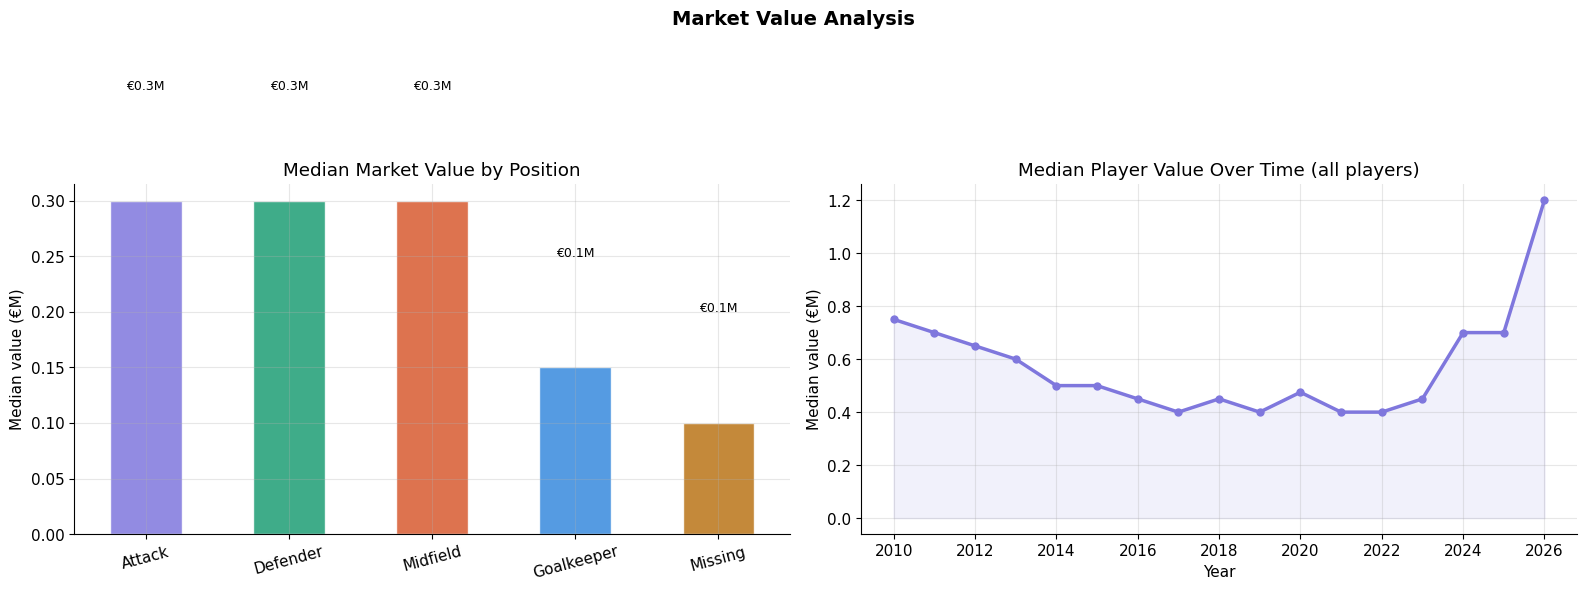

💾 Saved → reports/03_market_value_analysis.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Market Value Analysis', fontsize=14, fontweight='bold')

# 5a. Average market value by position
ax = axes[0]
avg_val = (
    players.groupby('position')['market_value_in_eur']
    .median()
    .sort_values(ascending=False) / 1e6
)
avg_val.plot.bar(ax=ax, color=COLORS[:len(avg_val)], alpha=0.85, edgecolor='white')
ax.set_title('Median Market Value by Position')
ax.set_ylabel('Median value (€M)')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'€{bar.get_height():.1f}M', ha='center', fontsize=9)

# 5b. Market value trend over years
ax = axes[1]
yearly = vals.groupby('year')['market_value_in_eur'].median() / 1e6
yearly = yearly[yearly.index >= 2010]
ax.plot(yearly.index, yearly.values, color=COLORS[0], linewidth=2.5, marker='o', markersize=5)
ax.fill_between(yearly.index, yearly.values, alpha=0.1, color=COLORS[0])
ax.set_title('Median Player Value Over Time (all players)')
ax.set_ylabel('Median value (€M)')
ax.set_xlabel('Year')

plt.tight_layout()
plt.savefig('../reports/03_market_value_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/03_market_value_analysis.png')

## 🔄 6 — Transfers Analysis

In [9]:
transfers = dfs['transfers'].copy()
transfers['transfer_date'] = pd.to_datetime(transfers['transfer_date'], errors='coerce')
transfers['year']  = transfers['transfer_date'].dt.year
transfers['fee_M'] = transfers['transfer_fee'] / 1e6

print(f"Total transfers:          {len(transfers):,}")
print(f"Transfers with fee > 0:   {(transfers['transfer_fee'] > 0).sum():,}")
print(f"Free transfers (fee = 0): {(transfers['transfer_fee'] == 0).sum():,}")
print(f"Max single transfer fee:  €{transfers['transfer_fee'].max()/1e6:.1f}M")
print(f"Avg fee (paid only):      €{transfers[transfers['transfer_fee']>0]['fee_M'].mean():.2f}M")

Total transfers:          157,186
Transfers with fee > 0:   16,513
Free transfers (fee = 0): 85,840
Max single transfer fee:  €222.0M
Avg fee (paid only):      €4.97M


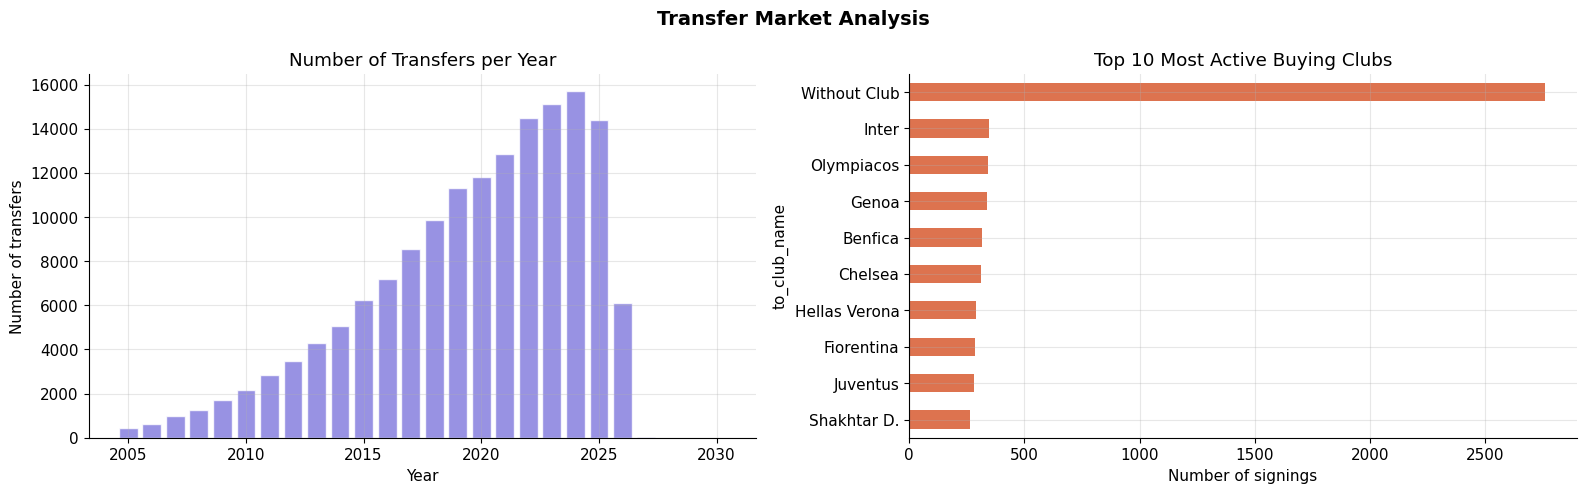

💾 Saved → reports/04_transfers_analysis.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Transfer Market Analysis', fontsize=14, fontweight='bold')

# 6a. Transfer volume per year
ax = axes[0]
yearly_transfers = transfers.groupby('year').size()
yearly_transfers = yearly_transfers[yearly_transfers.index >= 2005]
ax.bar(yearly_transfers.index, yearly_transfers.values, color=COLORS[0], alpha=0.8, edgecolor='white')
ax.set_title('Number of Transfers per Year')
ax.set_xlabel('Year')
ax.set_ylabel('Number of transfers')

# 6b. Top 10 most active buying clubs
ax = axes[1]
top_buyers = transfers['to_club_name'].value_counts().head(10)
top_buyers.plot.barh(ax=ax, color=COLORS[2], alpha=0.85)
ax.set_title('Top 10 Most Active Buying Clubs')
ax.invert_yaxis()
ax.set_xlabel('Number of signings')

plt.tight_layout()
plt.savefig('../reports/04_transfers_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/04_transfers_analysis.png')

## 📊 7 — Appearances & Career Stats

In [23]:
apps = dfs['appearances'].copy()
apps['date'] = pd.to_datetime(apps['date'], errors='coerce')

# Career totals per player
career = apps.groupby('player_id').agg(
    games         = ('appearance_id', 'count'),
    total_goals   = ('goals',         'sum'),
    total_assists = ('assists',        'sum'),
    total_minutes = ('minutes_played', 'sum'),
    yellow_cards  = ('yellow_cards',   'sum'),
    red_cards     = ('red_cards',      'sum'),
).reset_index()

career['goals_p90']   = (career['total_goals']   / (career['total_minutes'] / 90)).round(3)
career['assists_p90'] = (career['total_assists']  / (career['total_minutes'] / 90)).round(3)

# Merge with ALL player info we'll need for the rest of the notebook — do it ONCE here
career = career.merge(
    players[['player_id', 'name', 'position', 'age',
             'market_value_in_eur', 'current_club_name',
             'current_club_domestic_competition_id']],
    on='player_id', how='left'
)

print(f"Players with appearance data: {len(career):,}")
print(f"\nTop 10 career scorers (goals_p90, min 50 games):")
top_scorers = (
    career[career['games'] >= 50]
    .nlargest(10, 'goals_p90')
    [['name','position','games','total_goals','total_assists','goals_p90','assists_p90']]
)
print(top_scorers.to_string(index=False))

Players with appearance data: 28,665

Top 10 career scorers (goals_p90, min 50 games):
               name position  games  total_goals  total_assists  goals_p90  assists_p90
     Erling Haaland   Attack    282          247             50       0.97         0.20
  Cristiano Ronaldo   Attack    482          432            114       0.94         0.25
       Lionel Messi   Attack    526          452            224       0.91         0.45
      Kylian Mbappé   Attack    417          322            111       0.91         0.31
    Viktor Gyökeres   Attack    136          103             23       0.89         0.20
 Robert Lewandowski   Attack    656          525            121       0.88         0.20
      Sergio Agüero   Attack    323          220             57       0.86         0.22
Aleksandar Prijovic   Attack     89           57             10       0.85         0.15
         Franculino   Attack     83           45             13       0.85         0.24
         Harry Kane   Attack    5

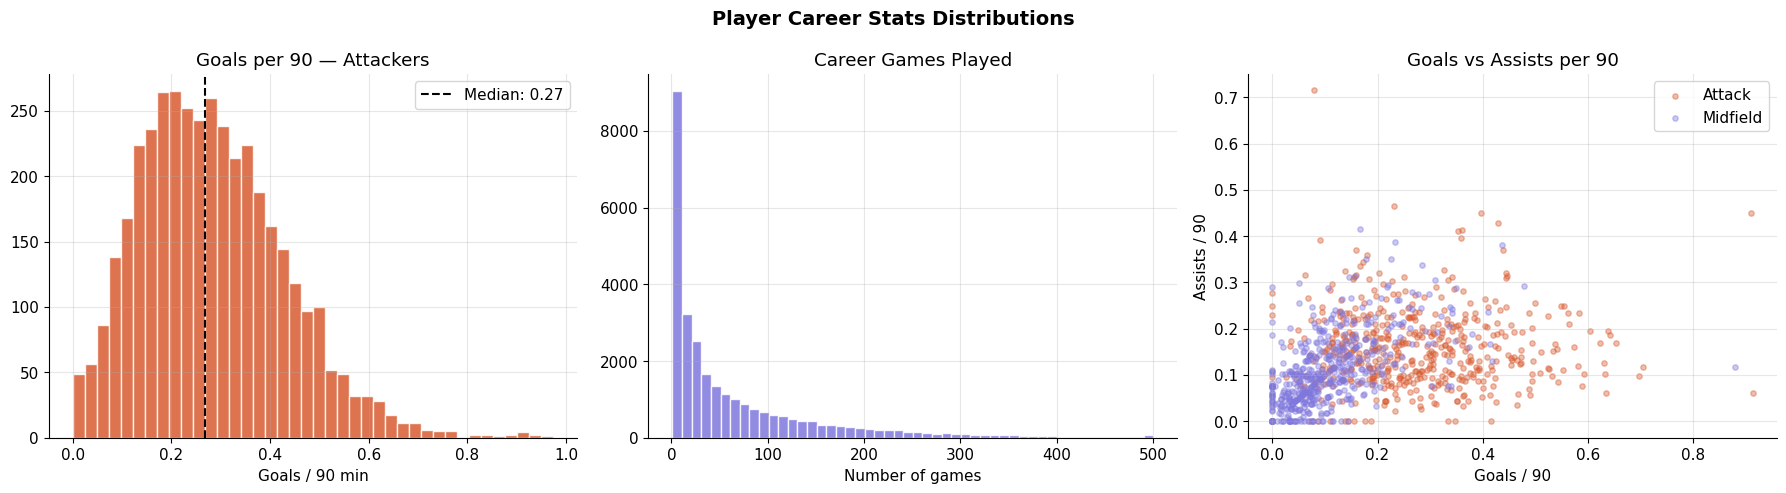

💾 Saved → reports/05_career_stats.png


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Player Career Stats Distributions', fontsize=14, fontweight='bold')

# 7a. Goals per 90 (attackers only)
ax = axes[0]
att = career[(career['position'] == 'Attack') & (career['games'] >= 30)]
ax.hist(att['goals_p90'].clip(0, 1.5), bins=40, color=COLORS[2], alpha=0.85, edgecolor='white')
ax.axvline(att['goals_p90'].median(), color='black', linestyle='--',
           label=f"Median: {att['goals_p90'].median():.2f}")
ax.set_title('Goals per 90 — Attackers')
ax.set_xlabel('Goals / 90 min')
ax.legend()

# 7b. Games played distribution
ax = axes[1]
ax.hist(career['games'].clip(0, 500), bins=50, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_title('Career Games Played')
ax.set_xlabel('Number of games')

# 7c. Goals vs assists scatter (attackers + midfielders)
ax = axes[2]
sub = career[(career['games'] >= 30) &
             (career['position'].isin(['Attack', 'Midfield']))].sample(min(1000, len(career)))
colors_map = {'Attack': COLORS[2], 'Midfield': COLORS[0]}
for pos, group in sub.groupby('position'):
    ax.scatter(group['goals_p90'].clip(0, 1.5), group['assists_p90'].clip(0, 1.0),
               alpha=0.4, s=15, color=colors_map.get(pos, 'gray'), label=pos)
ax.set_title('Goals vs Assists per 90')
ax.set_xlabel('Goals / 90')
ax.set_ylabel('Assists / 90')
ax.legend()

plt.tight_layout()
plt.savefig('../reports/05_career_stats.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/05_career_stats.png')

## 🌍 8 — Competitions & League Coverage

In [25]:
comps = dfs['competitions'].copy()

# First-tier leagues only
first_tier = comps[comps['sub_type'] == 'first_tier'].copy()

print(f"Total competitions in dataset: {len(comps)}")
print(f"First-tier domestic leagues:   {len(first_tier)}")
print(f"\nLeagues by confederation:")
print(first_tier['confederation'].value_counts().to_string())
print(f"\nAll first-tier leagues:")
print(first_tier[['competition_id','name','country_name','confederation']].to_string(index=False))

Total competitions in dataset: 67
First-tier domestic leagues:   32

Leagues by confederation:
confederation
europa     23
amerika     5
asien       4

All first-tier leagues:
competition_id                          name   country_name confederation
            A1                    bundesliga        Austria        europa
          ARG1               torneo-apertura      Argentina       amerika
          AUS1                  a-league-men      Australia         asien
           BE1            jupiler-pro-league        Belgium        europa
          BRA1 campeonato-brasileiro-serie-a         Brazil       amerika
            C1                  super-league    Switzerland        europa
          COL1          liga-betplay-dimayor       Colombia       amerika
           DK1                     superliga        Denmark        europa
           ES1                        laliga          Spain        europa
           FR1                       ligue-1         France        europa
          

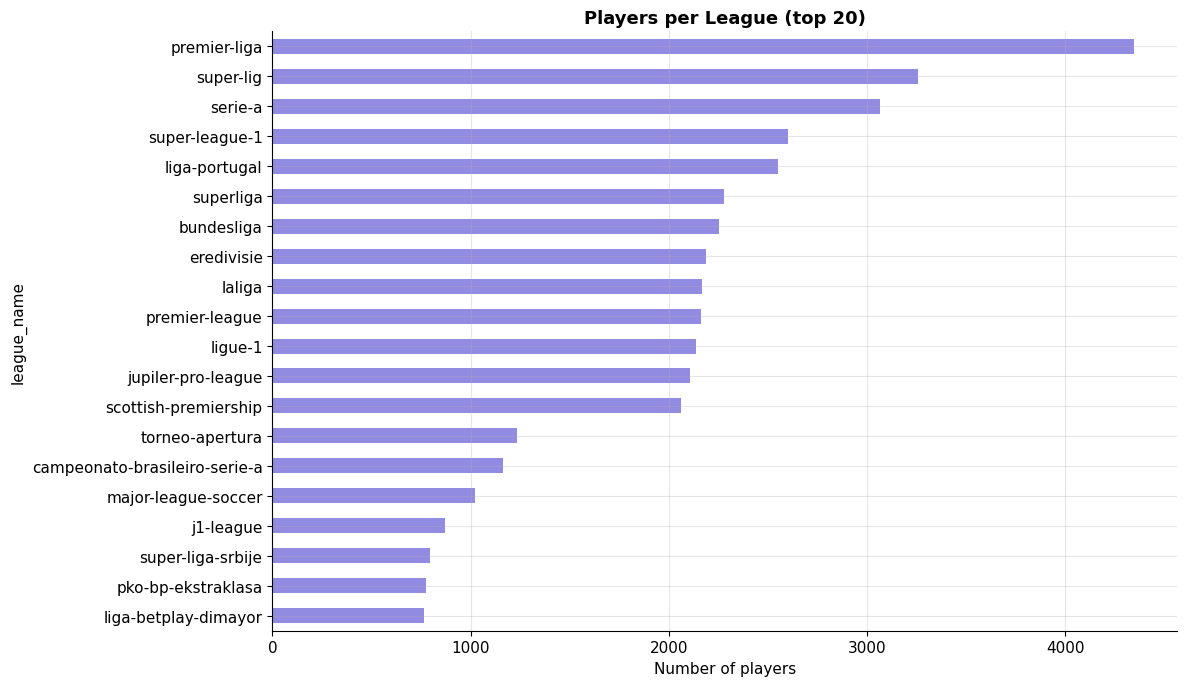

💾 Saved → reports/06_players_per_league.png


In [26]:
# Players per competition (via club → competition join)
players_per_comp = (
    players
    .merge(
        # ← rename 'name' to 'league_name' BEFORE merge to avoid conflict with players.name
        comps[['competition_id','name','country_name']].rename(columns={'name': 'league_name'}),
        left_on='current_club_domestic_competition_id',
        right_on='competition_id', how='left'
    )
    .groupby('league_name')['player_id'].count()   # ← now uses 'league_name' not 'name'
    .sort_values(ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(12, 7))
players_per_comp.plot.barh(ax=ax, color=COLORS[0], alpha=0.85)
ax.set_title('Players per League (top 20)', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of players')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/06_players_per_league.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/06_players_per_league.png')

## 🔗 9 — Join Quality Check

In [27]:
print("=" * 55)
print("  JOIN QUALITY REPORT")
print("=" * 55)

checks = [
    ('appearances → players',
     apps['player_id'].nunique(),
     apps['player_id'].isin(players['player_id']).mean() * 100),

    ('transfers → players',
     transfers['player_id'].nunique(),
     transfers['player_id'].isin(players['player_id']).mean() * 100),

    ('player_valuations → players',
     dfs['player_valuations']['player_id'].nunique(),
     dfs['player_valuations']['player_id'].isin(players['player_id']).mean() * 100),

    ('game_lineups → games',
     dfs['game_lineups']['game_id'].nunique(),
     dfs['game_lineups']['game_id'].isin(dfs['games']['game_id']).mean() * 100),

    ('appearances → games',
     apps['game_id'].nunique(),
     apps['game_id'].isin(dfs['games']['game_id']).mean() * 100),

    ('players → clubs',
     players['current_club_id'].nunique(),
     players['current_club_id'].isin(dfs['clubs']['club_id']).mean() * 100),
]

print(f"  {'Join':<35} {'Unique keys':>12} {'Match %':>8}")
print("  " + "─" * 55)
for label, unique, match_pct in checks:
    status = '✅' if match_pct > 90 else '⚠️ ' if match_pct > 70 else '❌'
    print(f"  {status} {label:<33} {unique:>12,} {match_pct:>7.1f}%")

  JOIN QUALITY REPORT
  Join                                 Unique keys  Match %
  ───────────────────────────────────────────────────────
  ✅ appearances → players                   28,665   100.0%
  ✅ transfers → players                     20,855   100.0%
  ✅ player_valuations → players             39,361    99.7%
  ✅ game_lineups → games                    78,141   100.0%
  ✅ appearances → games                     72,482   100.0%
  ✅ players → clubs                          1,751    94.3%


## 💡 10 — Age vs Market Value (Scouting Insight)

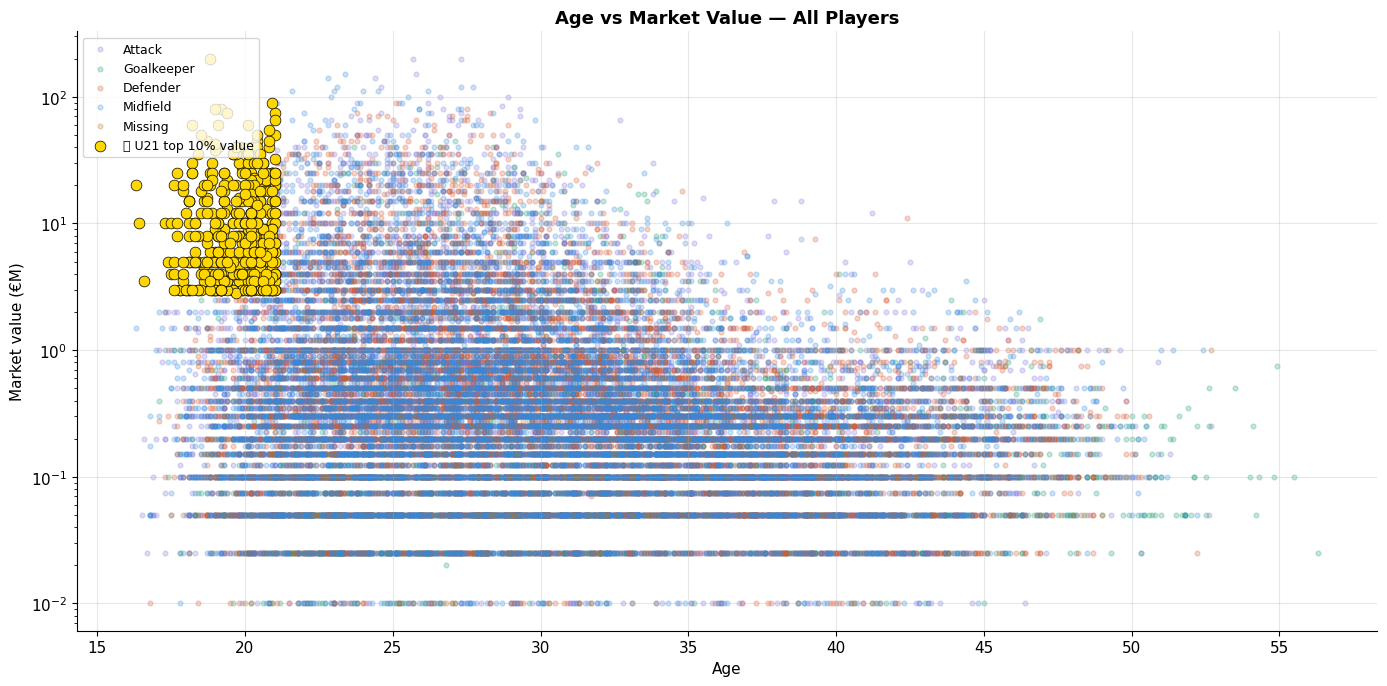


⭐ U21 high-value players found: 411
              name   age position  value_M€                 current_club_name
      Lamine Yamal 18.80   Attack    200.00             Futbol Club Barcelona
       Désiré Doué 20.90   Attack     90.00 Paris Saint-Germain Football Club
       Pau Cubarsí 19.20 Defender     80.00             Futbol Club Barcelona
           Estêvão 19.00   Attack     80.00             Chelsea Football Club
      Kenan Yıldız 21.00   Attack     75.00            Juventus Football Club
      Yan Diomande 19.40   Attack     75.00            RasenBallsport Leipzig
      Dean Huijsen 21.00 Defender     65.00        Real Madrid Club de Fútbol
Warren Zaïre-Emery 20.10 Midfield     60.00 Paris Saint-Germain Football Club
     Luka Vuskovic 19.10 Defender     60.00            Hamburger Sport Verein
      Lennart Karl 18.20 Midfield     60.00                 FC Bayern München
💾 Saved → reports/07_age_vs_value.png


In [28]:
scout = players[['player_id','name','age','position',
                 'market_value_in_eur','country_of_citizenship',
                 'current_club_name']].dropna(subset=['age','market_value_in_eur'])
scout = scout[scout['market_value_in_eur'] > 0]

fig, ax = plt.subplots(figsize=(14, 7))

positions = scout['position'].dropna().unique()
pos_colors = dict(zip(positions, COLORS))

for pos in positions:
    sub = scout[scout['position'] == pos]
    ax.scatter(
        sub['age'],
        sub['market_value_in_eur'] / 1e6,
        alpha=0.25, s=12,
        color=pos_colors.get(pos, 'gray'),
        label=pos
    )

# Highlight U21 high-value players (potential targets)
targets = scout[
    (scout['age'] <= 21) &
    (scout['market_value_in_eur'] >= scout['market_value_in_eur'].quantile(0.90))
]
ax.scatter(targets['age'], targets['market_value_in_eur'] / 1e6,
           color='gold', s=60, zorder=5, edgecolors='black',
           linewidth=0.5, label='⭐ U21 top 10% value')

ax.set_title('Age vs Market Value — All Players', fontsize=13, fontweight='bold')
ax.set_xlabel('Age')
ax.set_ylabel('Market value (€M)')
ax.set_yscale('log')
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/07_age_vs_value.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\n⭐ U21 high-value players found: {len(targets)}')
print(targets[['name','age','position','market_value_in_eur','current_club_name']]
      .nlargest(10, 'market_value_in_eur')
      .assign(market_value_in_eur=lambda x: (x['market_value_in_eur']/1e6).round(1))
      .rename(columns={'market_value_in_eur':'value_M€'})
      .to_string(index=False))
print('💾 Saved → reports/07_age_vs_value.png')

## 🏆 11 — Undervalued Players (Value Efficiency Preview)

In [29]:
# Value efficiency = (goals + assists) per million euros of market value
under = career[
    (career['market_value_in_eur'] > 100_000) &
    (career['games'] >= 30) &
    (career['age'].between(18, 27))
].copy()

under['value_efficiency'] = (
    (under['total_goals'] + under['total_assists']) /
    (under['market_value_in_eur'] / 1_000_000)
).round(3)

top_efficient = under.nlargest(15, 'value_efficiency')[[
    'name','age','position','games','total_goals','total_assists',
    'market_value_in_eur','value_efficiency','current_club_name'
]].copy()
top_efficient['value_M€'] = (top_efficient['market_value_in_eur'] / 1e6).round(2)
top_efficient.drop(columns='market_value_in_eur', inplace=True)

print('💎 Top 15 Most Efficient Players (U27, min 30 games):')
print('   High goals+assists relative to market value = undervalued gem\n')
print(top_efficient[['name','age','position','games','total_goals',
                      'total_assists','value_M€','value_efficiency',
                      'current_club_name']].to_string(index=False))

💎 Top 15 Most Efficient Players (U27, min 30 games):
   High goals+assists relative to market value = undervalued gem

                  name   age position  games  total_goals  total_assists  value_M€  value_efficiency                                        current_club_name
       Connor McLennan 26.50   Attack    136           12             11      0.15            153.33                                 Livingston Football Club
           Lewis Smith 26.10 Midfield     58            8              3      0.15             73.33                                 Livingston Football Club
        Thomas Buitink 25.80   Attack    157           17              7      0.35             68.57 Prins Hendrik Ende Desespereert Nimmer Combinatie Zwolle
       Glenn Middleton 26.30   Attack    121           11             12      0.35             65.71                              Dundee United Football Club
Dimitris Emmanouilidis 25.50   Attack    122           24              7      0.50         

## 📋 12 — Final EDA Summary

In [30]:
print("=" * 60)
print("  EDA SUMMARY — SCOUTI KORA")
print("=" * 60)

print(f"""
📦 DATASETS
  Total records across all tables:  {total_rows:>12,}
  Player profiles:                  {len(players):>12,}
  Valuation records:                {len(dfs['player_valuations']):>12,}
  Appearance records:               {len(apps):>12,}
  Transfer records:                 {len(transfers):>12,}

⚽ PLAYERS
  Total players:                    {len(players):>12,}
  Players with market value > 0:    {(players['market_value_in_eur']>0).sum():>12,}
  Average age:                      {players['age'].mean():>11.1f} yrs
  Median market value:              €{players['market_value_in_eur'].median()/1e6:>10.2f}M
  Max market value:                 €{players['market_value_in_eur'].max()/1e6:>10.0f}M

🌍 LEAGUES
  First-tier domestic leagues:      {len(first_tier):>12,}
  Confederations covered:           {first_tier['confederation'].nunique():>12,}

📊 CAREER STATS (players with 30+ games)
  Players with appearance data:     {len(career):>12,}
  Avg goals/90 (attackers):         {career[career['position']=='Attack']['goals_p90'].median():>11.3f}
  Total goals in dataset:           {career['total_goals'].sum():>12,}
  Total assists in dataset:         {career['total_assists'].sum():>12,}

✅ NEXT STEPS
  → notebook 02: FBref scraping (real-time stats for all 32+ leagues)
  → notebook 03: Feature engineering (per-90 KPIs, composite scores)
  → notebook 04: Model 1 — KNN similarity engine
""")

print("=" * 60)
print("  All EDA charts saved in reports/")
print("=" * 60)

  EDA SUMMARY — SCOUTI KORA

📦 DATASETS
  Total records across all tables:     7,238,299
  Player profiles:                        47,702
  Valuation records:                     616,377
  Appearance records:                  1,862,208
  Transfer records:                      157,186

⚽ PLAYERS
  Total players:                          47,702
  Players with market value > 0:          39,226
  Average age:                             29.2 yrs
  Median market value:              €      0.28M
  Max market value:                 €       200M

🌍 LEAGUES
  First-tier domestic leagues:                32
  Confederations covered:                      3

📊 CAREER STATS (players with 30+ games)
  Players with appearance data:           28,665
  Avg goals/90 (attackers):               0.185
  Total goals in dataset:                177,733
  Total assists in dataset:              139,864

✅ NEXT STEPS
  → notebook 02: FBref scraping (real-time stats for all 32+ leagues)
  → notebook 03: Feature en

In [31]:
# Save the career stats as an intermediate dataset for next notebooks
career.to_csv('../data/processed/career_stats.csv', index=False)
print(f'💾 Saved → data/processed/career_stats.csv  ({len(career):,} rows)')

💾 Saved → data/processed/career_stats.csv  (28,665 rows)
